### Online Shoppers Purchasing Intention 

#### Contexto
Uma empresa de e-commerce precisa de um sistema preditivo para identificar a propensão de compra de um usuário baseado em seu comportamento de navegação.

#### Dicionário de Dados
Verifique em: [Dicionário de Dados](../doc/data_dictionary_.md)

---

#### 1. Configuração do Ambiente

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

#### 2. Carregamento e Entendimento Inicial dos Dados

In [27]:
# Carrega o conjunto de dados e exibe os 5 primeiros registros
df = pd.read_csv("../data/raw/online_shoppers_intention.csv")

print(f"Shape dos dados: {df.shape}")
print("\nPrimeiras linhas do conjunto:")
df.head()

Shape dos dados: (12330, 18)

Primeiras linhas do conjunto:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [28]:
# Informações gerais sobre o dataset
print("=== INFORMAÇÕES GERAIS DO DATASET ===\n")
print(df.info())

print("\n=== ESTATÍSTICAS DESCRITIVAS ===\n")
df.describe(include="all")

=== INFORMAÇÕES GERAIS DO DATASET ===

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330,12330
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,NaN,NaN,NaN,NaN,3,2,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,May,NaN,NaN,NaN,NaN,Returning_Visitor,False,False
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3364,NaN,NaN,NaN,NaN,10551,9462,10422
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,NaN,2.124006,2.357097,3.147364,4.069586,NaN,NaN,NaN
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,NaN,0.911325,1.717277,2.401591,4.025169,NaN,NaN,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,1.000000,1.000000,1.000000,1.000000,NaN,NaN,NaN
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,NaN,2.000000,2.000000,1.000000,2.000000,NaN,NaN,NaN
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,NaN,2.000000,2.000000,3.000000,2.000000,NaN,NaN,NaN
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,NaN,3.000000,2.000000,4.000000,4.000000,NaN,NaN,NaN


#### 3. Análise Exploratória de Dados (EDA)

##### 3.1. Análise de Valores Faltantes

In [29]:
missing_values = pd.DataFrame(
    {
        "Coluna": df.columns,
        "Missing_Count": df.isnull().sum(),
        "Missing_Percentage": (df.isnull().sum() / len(df) * 100).round(2),
    }
)

missing_values = missing_values[missing_values["Missing_Count"].gt(0)].sort_values(
    by="Missing_Percentage", ascending=False
)

missing_values

,Coluna,Missing_Count,Missing_Percentage


Nenhma coluna possui valores faltantes.

De qualquer maneira, abaixo construiremos um gráfico para visualização da proporção de valores faltantes por coluna, para futura referência.

In [30]:
if len(missing_values) > 0:
    print(missing_values)

    plt.figure(figsize=(10, 3))
    plt.barh(
        missing_values["Coluna"], missing_values["Missing_Percentage"], color="coral"
    )
    plt.xlabel("Porcentagem de Missing Values (%)")
    plt.title("Distribuição de Missing Values por Coluna")
    plt.tight_layout()
    plt.show()
else:
    print("Nenhum valor faltante detectado!")

Nenhum valor faltante detectado!


##### 3.2. Análise da Variável Alvo

In [31]:
# Renomear variável `Revenue` para `target`
df = df.rename(columns={"Revenue": "target"})

Uma análise dos valores únicos da variável alvo nos mostra que ela já está binarizada e é do tipo bool (conforme `df.info()`). Vamos convertê-la para valores inteiros.

In [32]:
df["target"].unique()

array([False,  True])

In [33]:
df["target"] = df["target"].map(int)

Contagem:
target
0    10422
1     1908
Name: count, dtype: int64

Percentual:
Não propenso (0): 84.53%
Propenso (1): 15.47%


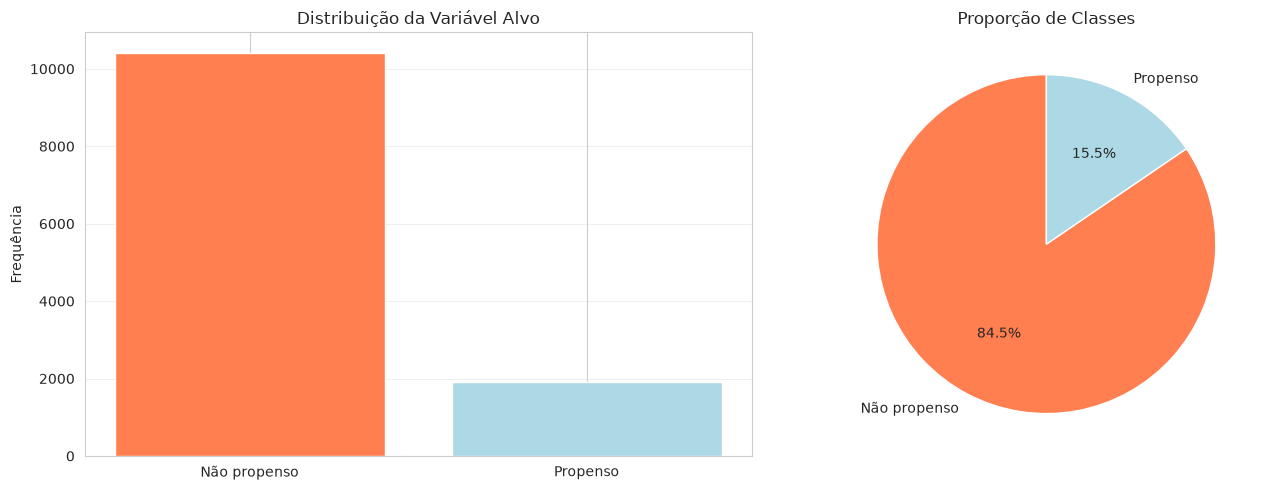


Razão de balanceamento: 0.18
Dataset desbalanceado! Considere usar técnicas como SMOTE ou class_weight.


In [35]:
target_counts = df["target"].value_counts()
target_percentages = df["target"].value_counts(normalize=True) * 100

print("Contagem:")
print(target_counts)

print("\nPercentual:")
for idx, pct in target_percentages.items():
    label = "Propenso" if idx == 1 else "Não propenso"
    print(f"{label} ({idx}): {pct:.2f}%")

# Visualização
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Gráfico de barras
axes[0].bar(["Não propenso", "Propenso"], target_counts.values, color=["coral", "lightblue"])
axes[0].set_ylabel('Frequência')
axes[0].set_title('Distribuição da Variável Alvo')
axes[0].grid(axis='y', alpha=0.3)

# Gráfico de pizza
axes[1].pie(target_counts.values, labels=["Não propenso", "Propenso"], autopct="%1.1f%%", colors=["coral", "lightblue"], startangle=90)
axes[1].set_title('Proporção de Classes')
plt.tight_layout()
plt.show()

# Verifição de desbalanceamento
ratio = target_counts.min() / target_counts.max()
print(f"\nRazão de balanceamento: {ratio:.2f}")
if ratio < 0.5:
    print("Dataset desbalanceado! Considere usar técnicas como SMOTE ou class_weight.")
else:
    print("Dataset razoavelmente balanceado.")

##### 3.3 Análise de Outliers
Objetivo: Identificar valores extremos que podem ser erros de medição ou casos especiais

Métodos utilizados:

- Z-Score: Identifica valores que estão a mais de 3 desvios padrão da média
- Visualização: Boxplots para identificação visual

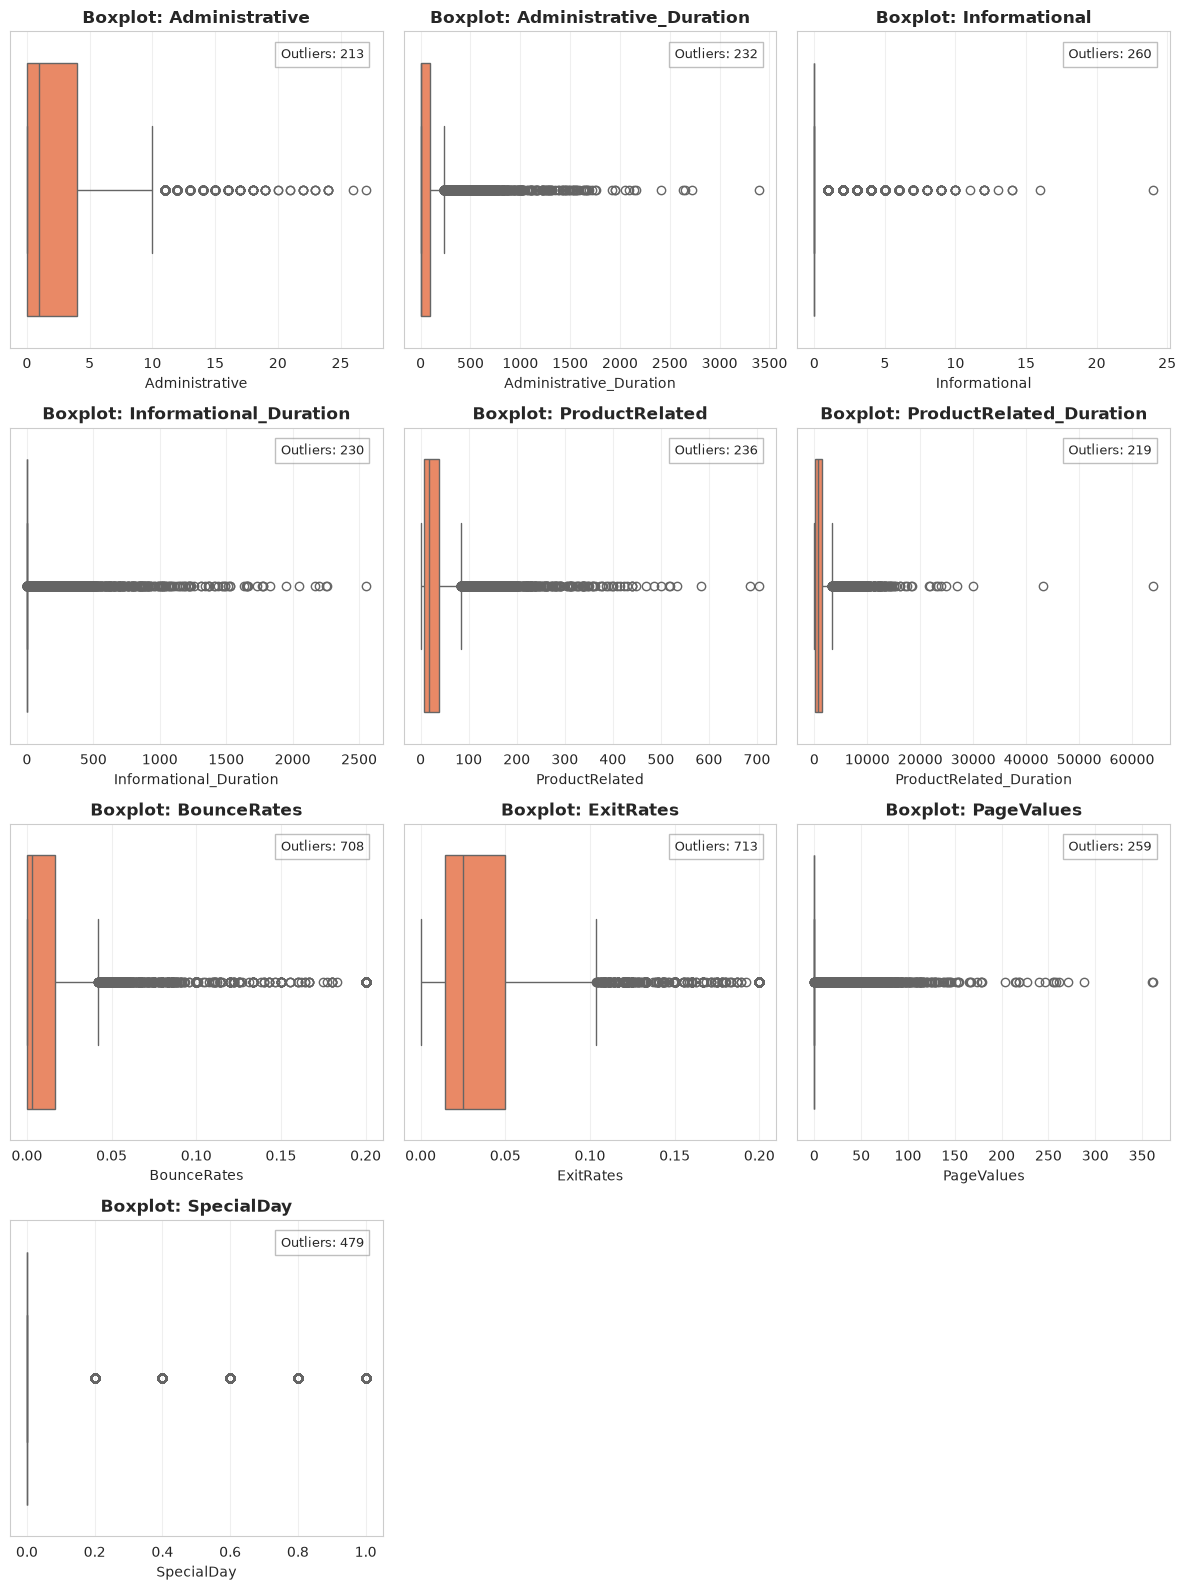

In [39]:
# Colunas numéricas (excluindo colunas que nao fazem sentido para análise de outliers)
numeric_cols = df.select_dtypes(include=[np.number]).columns
numeric_cols = numeric_cols.drop(["target", "OperatingSystems", "Browser", "Region", "TrafficType"])

n = len(numeric_cols)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4 * nrows))
axes = axes.ravel()

for idx, col in enumerate(numeric_cols):
    sns.boxplot(x=df[col], ax=axes[idx], color="coral")
    axes[idx].set_title(f"Boxplot: {col}", fontweight="bold")
    axes[idx].set_xlabel(col)
    axes[idx].grid(axis="x", alpha=0.3)
    col_zscore = np.abs(stats.zscore(df[col].dropna()))
    outlier_count = (col_zscore > 3).sum()
    axes[idx].text(
        0.95,
        0.95,
        f"Outliers: {outlier_count}",
        transform=axes[idx].transAxes,
        fontsize=9,
        verticalalignment="top",
        horizontalalignment="right",
        bbox={"facecolor": "white", "alpha": 0.5, "edgecolor": "gray"},
    )

for ax in axes[n:]:
    fig.delaxes(ax)

plt.tight_layout()

##### 3.4 Propensão por Mês
Sazonalidade pode influenciar propensão à compras.

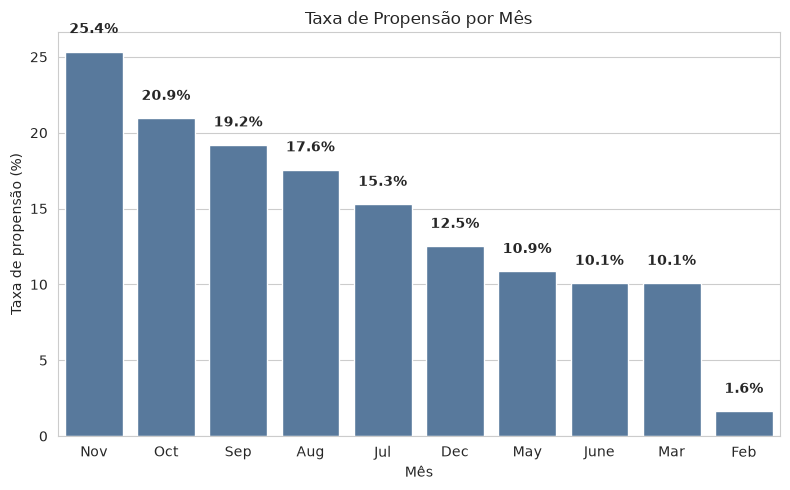

In [41]:
month_rate = (
    df.groupby("Month")["target"]
    .mean()
    .sort_values(ascending=False)
    .mul(100)
    .rename("Propensão (%)")
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=month_rate.index, y=month_rate.values, color="#4C78A8", ax=ax)

ax.set_title("Taxa de Propensão por Mês")
ax.set_xlabel("Mês")
ax.set_ylabel("Taxa de propensão (%)")

for i, value in enumerate(month_rate.values):
    ax.text(i, value + 1, f"{value:.1f}%", ha="center", va="bottom", fontweight="bold")

fig.tight_layout()

##### 3.5 Propensão por Tipo de Visitante
Um visitante recorrente pode ser mais propenso a realizar uma compra.

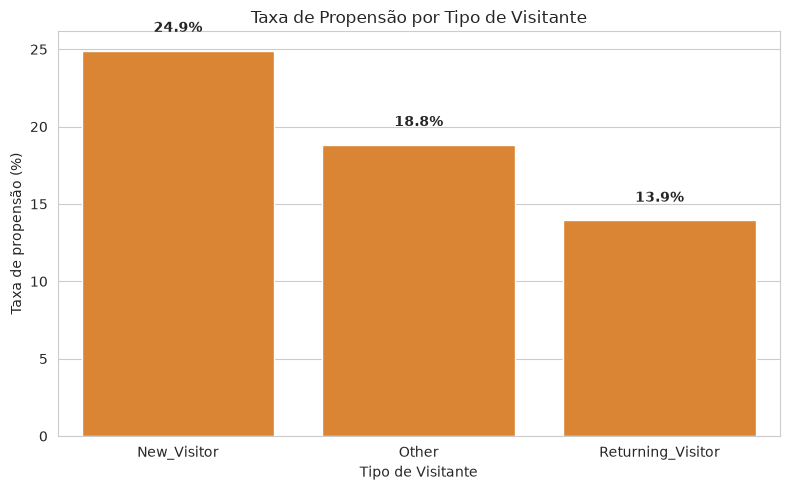

In [44]:
visitor_rate = (
    df.groupby("VisitorType")["target"]
        .mean()
        .sort_values(ascending=False)
        .mul(100)
        .rename("Propensão (%)")
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=visitor_rate.index, y=visitor_rate.values, color="#F58518", ax=ax)

ax.set_title("Taxa de Propensão por Tipo de Visitante")
ax.set_xlabel("Tipo de Visitante")
ax.set_ylabel("Taxa de propensão (%)")

for i, value in enumerate(visitor_rate.values):
    ax.text(i, value + 1, f"{value:.1f}%", ha="center", va="bottom", fontweight="bold")

fig.tight_layout()

#### 4. Preparação dos dados

##### 4.1. Padronização do nome de colunas

In [45]:
# Renomeia colunas para lowercase e separação por underscore
df.columns = ["_".join(i.lower().split(" ")) for i in df.columns]

##### 4.2. Persistência do dataset limpo

In [47]:
df.to_csv("../data/processed/online_shoppers_intention.csv", index=False)